<div style="background:#0d0d0d; padding:32px 40px; border-radius:12px; border-left:5px solid #7B61FF;">
<h1 style="color:#FFFFFF; font-family:monospace; margin:0 0 8px 0; font-size:26px;">
  🔦 Beam Search: Greedy Picks the Best Next Word, Not the Best Sentence
</h1>
<p style="color:#9E9E9E; font-size:14px; margin:0;">
  Decoding Complexities · companion notebook
</p>
</div>

---

### What this notebook covers

| Section | Concept |
|---|---|
| 1 | Load a small, free model — inference only, no training — plus a helper that scores any sequence |
| 2 | The trap — the first-word distribution is nearly flat, and greedy takes the top word by a tiny margin |
| 3 | Greedy vs. beam search — same model, same prompt, different sequence score |
| 4 | Beam search by hand — the first two steps, traced with real probabilities |
| 5 | Is it foolproof? — how many beams does it take to find the better sentence? |
| 6 | Figures for the blog and the video |

We are not pre-deciding what the model will say. Whatever it actually outputs is what goes into the blog
and the script, per this repo's narrative-evidence-alignment rule.

### Honest framing, decided before building

- **A higher sequence score is not the same as a true answer.** Here the higher-scoring sentence also happens to be
  the correct one, but that coincidence is not a general guarantee. The sequence score measures how likely
  the *model* thinks a sentence is.
- **Raw text completion, not chat.** The prompt is plain text fed straight to the model, with no chat template —
  different from the chat-template demo in the Greedy vs. Sampling notebook.
- **Fixed 15-token window, no length penalty.** We force every candidate to the same length
  (`min_new_tokens == max_new_tokens`, `length_penalty=0.0`) so sequence scores are directly comparable. Length
  penalties and beam search's tendency toward bland text are separate topics, parked.
- **Pure greedy, no sampling, no repetition penalty.** This model's shipped `generation_config` sets `do_sample=True`
  and `repetition_penalty=1.1`. We override both (`do_sample=False`, `repetition_penalty=1.0`) so that
  `num_beams=1` is genuinely "always take the single likeliest token". Left at the default, the greedy baseline
  scored -20.953 instead of -18.610, which would have inflated the gap against beam search.

### Recording note

Like the previous decoding notebook, this one is run once, in advance, and recorded as-is. Model load takes ~20s
and each generation call a few seconds; showing that live would be dead time.

**Demo prompt, locked:** `"In 1969, humans first"` — do not paraphrase this later; every number downstream traces
back to this exact wording.

**Pinned for reproducibility:** `Qwen/Qwen2.5-0.5B-Instruct`, `transformers==5.18.0`, `torch==2.14.1`.
Greedy and beam search are deterministic for this exact model + library combination — a different version could
change wording or scores.

In [1]:
# Section 1 -- load a small, free model. No training, inference only.
from transformers import AutoModelForCausalLM, AutoTokenizer
import torch

MODEL_NAME = "Qwen/Qwen2.5-0.5B-Instruct"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=torch.float32)
model.eval()
print(f"Loaded {MODEL_NAME} -- {model.num_parameters():,} parameters.")

PROMPT = "In 1969, humans first"
N_TOKENS = 15
prompt_ids = tokenizer(PROMPT, return_tensors="pt")["input_ids"]


def next_token_probs(ids, top=5):
    # Probability distribution over the next token, as (token_text, probability) pairs
    with torch.no_grad():
        probs = torch.softmax(model(ids).logits[0, -1], dim=-1)
    top_p, top_i = probs.topk(top)
    return [(tokenizer.decode(i), p.item()) for i, p in zip(top_i, top_p)]


def sequence_logprob(prompt_ids, generated_ids):
    # Sum of log P(token | everything before it) over the generated tokens only
    full = torch.cat([prompt_ids[0], generated_ids]).unsqueeze(0)
    with torch.no_grad():
        log_probs = torch.log_softmax(model(full).logits[0, :-1], dim=-1)
    targets = full[0, 1:]
    per_token = log_probs[torch.arange(len(targets)), targets]
    return per_token[prompt_ids.shape[1] - 1:].sum().item()


def decode(num_beams):
    # Fixed 15-token length and no length penalty, so scores compare like for like.
    # repetition_penalty=1.0 matters: Qwen's generation_config ships 1.1, which would
    # make "greedy" pick tokens other than the model's own highest-probability ones.
    kwargs = dict(
        max_new_tokens=N_TOKENS,
        min_new_tokens=N_TOKENS,
        do_sample=False,
        repetition_penalty=1.0,
        temperature=None,
        top_p=None,
        top_k=None,
        pad_token_id=tokenizer.eos_token_id,
    )
    if num_beams > 1:
        kwargs.update(num_beams=num_beams, early_stopping=False, length_penalty=0.0)
    out = model.generate(prompt_ids, attention_mask=torch.ones_like(prompt_ids), **kwargs)
    generated = out[0][prompt_ids.shape[1]:]
    return generated, sequence_logprob(prompt_ids, generated)


Loaded Qwen/Qwen2.5-0.5B-Instruct -- 494,032,768 parameters.


In [2]:
# Section 2 -- the trap: the first-word distribution is nearly flat
step1 = next_token_probs(prompt_ids, top=5)
print(f"Prompt: {PROMPT!r}\n")
print("Step 1 -- top 5 candidates for the first word:")
for token, p in step1:
    print(f"  {token!r:<18} {p:.2%}")

gap = step1[0][1] - step1[2][1]
print(f"\nGreedy takes {step1[0][0]!r}; {step1[2][0]!r} is only {gap * 100:.2f} percentage points behind.")
print(f"Its lead over the runner-up {step1[1][0]!r}: {(step1[0][1] - step1[1][1]) * 100:.2f} percentage points.")

# What does each choice lead into at step 2?
for word in [" used", " landed"]:
    ids = tokenizer(PROMPT + word, return_tensors="pt")["input_ids"]
    print(f"\nStep 2 after {word!r} -- top 3 next words:")
    for token, p in next_token_probs(ids, top=3):
        print(f"  {token!r:<18} {p:.2%}")


Prompt: 'In 1969, humans first'

Step 1 -- top 5 candidates for the first word:
  ' used'            7.84%
  ' successfully'    7.65%
  ' landed'          6.59%
  ' discovered'      5.92%
  ' achieved'        4.62%

Greedy takes ' used'; ' landed' is only 1.25 percentage points behind.
Its lead over the runner-up ' successfully': 0.19 percentage points.

Step 2 after ' used' -- top 3 next words:
  ' the'             17.87%
  ' a'               8.58%
  ' computers'       7.47%

Step 2 after ' landed' -- top 3 next words:
  ' a'               38.32%
  ' on'              33.08%
  ' the'             6.64%


In [3]:
# Section 3 -- greedy vs. beam search: same model, same prompt, same 15-token length
greedy_ids, greedy_score = decode(num_beams=1)
beam_ids, beam_score = decode(num_beams=4)

print(f"Greedy  (score {greedy_score:.3f}): {PROMPT}{tokenizer.decode(greedy_ids)}")
print(f"Beam x4 (score {beam_score:.3f}): {PROMPT}{tokenizer.decode(beam_ids)}")

# A sequence score is a sum of log-probabilities, so a gap of d means exp(d) times more likely
ratio = torch.exp(torch.tensor(beam_score - greedy_score)).item()
print(f"\nScore gap: {beam_score - greedy_score:.3f}  ->  beam's sentence is {ratio:,.0f}x more probable than greedy's")

# Determinism check: both strategies are deterministic, so a second run must match exactly
greedy_again, _ = decode(num_beams=1)
beam_again, _ = decode(num_beams=4)
print(f"\nGreedy identical on re-run: {torch.equal(greedy_ids, greedy_again)}")
print(f"Beam   identical on re-run: {torch.equal(beam_ids, beam_again)}")


Greedy  (score -18.610): In 1969, humans first used the Internet to communicate. In 2000, the Internet
Beam x4 (score -11.754): In 1969, humans first landed a man on the moon. In 2009, the

Score gap: 6.857  ->  beam's sentence is 950x more probable than greedy's



Greedy identical on re-run: True
Beam   identical on re-run: True


In [4]:
# Section 4 -- beam search by hand: width 3, first two steps only
WIDTH = 3


def top_k_log_probs(ids, k):
    with torch.no_grad():
        log_probs = torch.log_softmax(model(ids).logits[0, -1], dim=-1)
    top_lp, top_i = log_probs.topk(k)
    return list(zip(top_i.tolist(), top_lp.tolist()))


# Step 1: keep the 3 best first words (greedy would keep only 1)
beams = [([tok], lp) for tok, lp in top_k_log_probs(prompt_ids, WIDTH)]
print("After step 1, beam search keeps:")
for toks, lp in beams:
    print(f"  {tokenizer.decode(toks)!r:<18} joint probability {torch.exp(torch.tensor(lp)).item():.2%}")

# Step 2: extend every kept beam by its 3 best next words, then keep the 3 best two-word sequences overall
candidates = []
for toks, lp in beams:
    ids = torch.cat([prompt_ids[0], torch.tensor(toks)]).unsqueeze(0)
    for tok, next_lp in top_k_log_probs(ids, WIDTH):
        candidates.append((toks + [tok], lp + next_lp))
candidates.sort(key=lambda c: c[1], reverse=True)

print(f"\nStep 2 -- all {len(candidates)} candidates, ranked by joint probability:")
for rank, (toks, lp) in enumerate(candidates, start=1):
    marker = "KEPT   " if rank <= WIDTH else "dropped"
    print(f"  {marker} {tokenizer.decode(toks)!r:<28} {torch.exp(torch.tensor(lp)).item():.2%}")


After step 1, beam search keeps:
  ' used'            joint probability 7.84%
  ' successfully'    joint probability 7.65%
  ' landed'          joint probability 6.59%

Step 2 -- all 9 candidates, ranked by joint probability:
  KEPT    ' landed a'                  2.53%
  KEPT    ' landed on'                 2.18%
  KEPT    ' successfully cultivated'   2.00%
  dropped ' used the'                  1.40%
  dropped ' successfully landed'       1.00%
  dropped ' used a'                    0.67%
  dropped ' used computers'            0.59%
  dropped ' landed the'                0.44%
  dropped ' successfully developed'    0.37%


In [5]:
# Section 5 -- is it foolproof? Sweep beam width (width 1 is greedy)
WIDTHS = [1, 2, 3, 4, 8]
sweep = {}
for w in WIDTHS:
    ids, score = decode(num_beams=w)
    sweep[w] = (tokenizer.decode(ids), score)
    print(f"width {w}: score {score:.3f}  {PROMPT}{sweep[w][0]}")

best_width_score = max(score for _, score in sweep.values())
first_to_find = min(w for w, (_, score) in sweep.items() if score == best_width_score)
print(f"\nBest score in this sweep: {best_width_score:.3f}, first reached at width {first_to_find}")
print(f"Width 2 beats greedy ({sweep[2][1]:.3f} vs {sweep[1][1]:.3f}) but still misses the best sentence.")


width 1: score -18.610  In 1969, humans first used the Internet to communicate. In 2000, the Internet


width 2: score -14.984  In 1969, humans first successfully cultivated the first genetically modified organism (GMO) in the United States


width 3: score -11.754  In 1969, humans first landed a man on the moon. In 2009, the


width 4: score -11.754  In 1969, humans first landed a man on the moon. In 2009, the


width 8: score -11.754  In 1969, humans first landed a man on the moon. In 2009, the

Best score in this sweep: -11.754, first reached at width 3
Width 2 beats greedy (-14.984 vs -18.610) but still misses the best sentence.


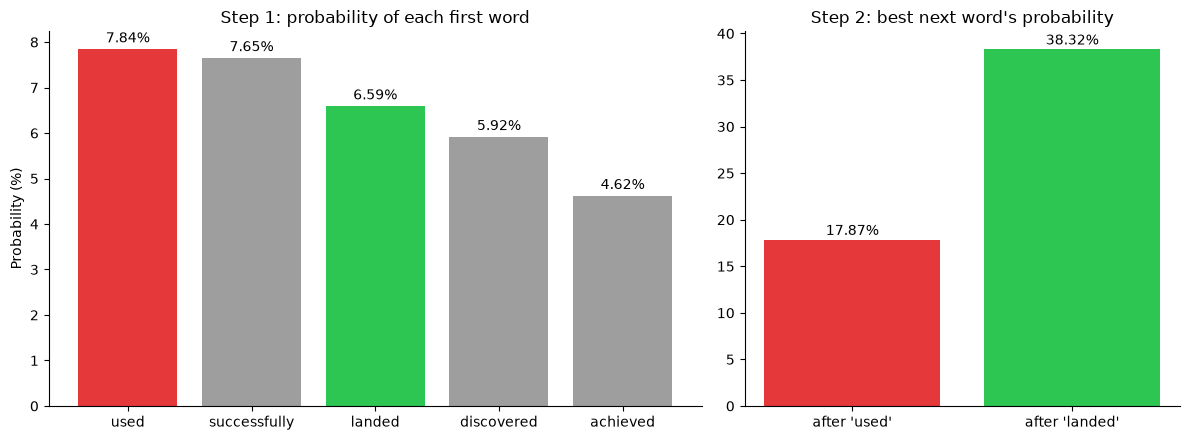

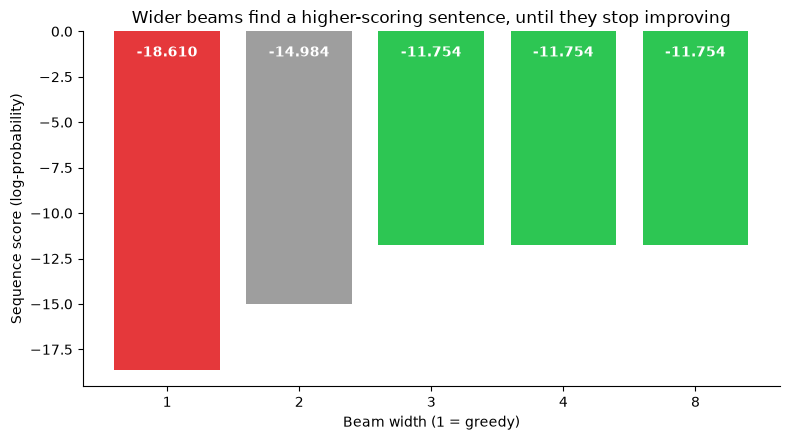

['BeamSearch_beam_width_scores.png', 'BeamSearch_step1_vs_step2.png']


In [6]:
# Section 6 -- figures for the blog and the video (black/white/red/green palette)
import os
import matplotlib.pyplot as plt

os.makedirs("assets", exist_ok=True)
RED, GREEN, GREY = "#E5383B", "#2DC653", "#9E9E9E"

# Figure 1 -- step 1 is nearly flat, but the best step-2 follow-up differs sharply by first word
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), gridspec_kw={"width_ratios": [3, 2]})
labels = [t.strip() for t, _ in step1]
colors = [RED if t == " used" else GREEN if t == " landed" else GREY for t, _ in step1]
ax1.bar(labels, [p * 100 for _, p in step1], color=colors)
ax1.set_title("Step 1: probability of each first word")
ax1.set_ylabel("Probability (%)")
for i, (_, p) in enumerate(step1):
    ax1.text(i, p * 100 + 0.15, f"{p:.2%}", ha="center")

best_after = {}
for word in [" used", " landed"]:
    ids = tokenizer(PROMPT + word, return_tensors="pt")["input_ids"]
    best_after[word] = next_token_probs(ids, top=1)[0][1]
ax2.bar(["after 'used'", "after 'landed'"], [v * 100 for v in best_after.values()], color=[RED, GREEN])
ax2.set_title("Step 2: best next word's probability")
for i, v in enumerate(best_after.values()):
    ax2.text(i, v * 100 + 0.5, f"{v:.2%}", ha="center")
for ax in (ax1, ax2):
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("assets/BeamSearch_step1_vs_step2.png", dpi=150)
plt.show()

# Figure 2 -- sequence score by beam width (higher, i.e. closer to 0, is better)
fig, ax = plt.subplots(figsize=(8, 4.5))
scores = [sweep[w][1] for w in WIDTHS]
bar_colors = [RED if w == 1 else GREY if s < best_width_score else GREEN for w, s in zip(WIDTHS, scores)]
ax.bar([str(w) for w in WIDTHS], scores, color=bar_colors)
ax.set_xlabel("Beam width (1 = greedy)")
ax.set_ylabel("Sequence score (log-probability)")
ax.set_title("Wider beams find a higher-scoring sentence, until they stop improving")
for i, s in enumerate(scores):
    ax.text(i, -0.8, f"{s:.3f}", ha="center", va="top", color="white", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("assets/BeamSearch_beam_width_scores.png", dpi=150)
plt.show()
print(os.listdir("assets"))


---
## What the Run Showed

- **The trap:** the first-word distribution is nearly flat (` used` 7.84%, ` successfully` 7.65%, ` landed` 6.59%). Greedy takes ` used`, 0.19 points ahead of ` successfully` and 1.25 ahead of ` landed`.
- **The cost:** after ` used`, the best next word is 17.87%. After ` landed`, it is 38.32%. The slightly-worse first word leads to a much stronger path.
- **Greedy vs. beam (4 beams), 15 tokens:** -18.610 vs. -11.754, a gap of 6.857, so beam's sentence is 950x more probable under the model. Both strategies were identical on re-run.
- **By hand (width 3):** after step 2, every ` used ...` candidate is dropped (the best, ` used the`, ranks 4th at 1.40%, outside the 3 kept).
- **Not foolproof:** width 2 improves on greedy (-14.984) but still misses the best sentence; width 3, 4 and 8 all reach -11.754.

### What this does NOT show

- The higher-scoring sentence is also the correct one here, but sequence score measures what the *model* finds likely, not what is true.
- Results are for one prompt, a 15-token window and no length penalty. Nothing here says beam search is better in general.
- This is raw text completion, not chat; nothing here says what chat products do.